# New York Taxi Trips: When, Where and Who Tips? 🚕
**Question:** when and where do New Yorkers take taxis, what drives the price, and who tips the most?

**Data:** a sample of 6,433 yellow and green taxi trips in New York City in March 2019, from the NYC Taxi & Limousine Commission (via the [seaborn example datasets](https://github.com/mwaskom/seaborn-data)), plus a zone-to-borough lookup table.

**Steps:** load and inspect → clean → merge in boroughs → feature engineering → analysis → charts → findings.

## 1. Load and inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

trips = pd.read_csv("data/taxi_trips.csv")
zones = pd.read_csv("data/zones.csv")
print(trips.shape, zones.shape)
trips.head()

(6448, 12) (213, 2)


,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone
0,2019-03-18 07:12:17,2019-03-18 08:03:24,1,9.30,36.5,0.00,11.52,48.82,green,credit card,Stuyvesant Heights,Midtown Center
1,2019-03-10 11:11:51,2019-03-10 11:18:23,6,1.06,6.5,0.00,0.00,9.80,yellow,cash,Murray Hill,Gramercy
2,2019-03-14 22:05:31,2019-03-14 22:27:53,4,4.90,18.5,4.46,0.00,26.76,yellow,credit card,Greenwich Village South,East Harlem South
3,2019-03-11 09:44:03,2019-03-11 10:19:55,0,9.10,31.5,8.10,5.76,48.66,yellow,credit card,LaGuardia Airport,Midtown Center
4,2019-03-22 08:26:07,2019-03-22 08:42:56,1,2.10,12.0,3.05,0.00,18.35,yellow,credit card,Greenwich Village South,Midtown East


In [2]:
trips.describe().round(2)

,passengers,distance,fare,tip,tolls,total
count,6448.00,6448.00,6448.00,6448.00,6448.00,6448.00
mean,1.54,3.03,13.09,1.98,0.33,18.52
std,1.20,3.83,11.55,2.45,1.42,13.81
min,0.00,0.00,1.00,0.00,0.00,1.30
25%,1.00,0.99,6.50,0.00,0.00,10.80
50%,1.00,1.64,9.50,1.70,0.00,14.16
75%,2.00,3.21,15.00,2.80,0.00,20.30
max,6.00,36.70,150.00,33.20,24.02,174.82


In [3]:
trips.isna().sum()

pickup           0
dropoff          0
passengers       0
distance         0
fare             0
tip              0
tolls            0
total            0
color            0
payment         44
pickup_zone     26
dropoff_zone    45
dtype: int64

**Problems found:**
- `passengers` and `distance` both have a minimum of **0**, which is impossible for a real trip
- `payment` has missing values and inconsistent spelling
- `pickup_zone` / `dropoff_zone` have missing values
- `pickup` and `dropoff` are stored as text, not dates

## 2. Clean

In [4]:
print("Payment spellings before:", trips["payment"].nunique())
trips["payment"] = trips["payment"].str.strip().str.lower()
trips["payment"] = trips["payment"].fillna("unknown")
trips["payment"].value_counts()

Payment spellings before: 6


payment
credit card    4590
cash           1814
unknown          44
Name: count, dtype: int64

In [5]:
print("Duplicate rows:", trips.duplicated().sum())
trips = trips.drop_duplicates()

bad = (trips["passengers"] == 0) | (trips["distance"] == 0)
print("Impossible trips (0 passengers or 0 distance):", bad.sum())
trips = trips[~bad]

trips["pickup"] = pd.to_datetime(trips["pickup"])
trips["dropoff"] = pd.to_datetime(trips["dropoff"])
print("Rows after cleaning:", len(trips))

Duplicate rows: 15
Impossible trips (0 passengers or 0 distance): 146
Rows after cleaning: 6287


## 3. Merge in the borough for each pickup zone

In [6]:
df = trips.merge(zones, left_on="pickup_zone", right_on="zone", how="left")
df = df.drop(columns="zone").rename(columns={"borough": "pickup_borough"})
print("Rows after merge:", len(df), "(unchanged, as expected for a left merge)")
print("Trips with no borough:", df["pickup_borough"].isna().sum())
df["pickup_borough"] = df["pickup_borough"].fillna("Unknown")

Rows after merge: 6287 (unchanged, as expected for a left merge)
Trips with no borough: 15


## 4. Feature engineering

In [7]:
df["duration_min"] = (df["dropoff"] - df["pickup"]).dt.total_seconds() / 60
df["hour"] = df["pickup"].dt.hour
df["weekday"] = df["pickup"].dt.day_name()
df["tip_pct"] = df["tip"] / df["fare"] * 100
df["tipped"] = np.where(df["tip"] > 0, "yes", "no")
df["trip_length"] = pd.cut(df["distance"], bins=[0, 1, 3, 40], labels=["short", "medium", "long"])

def time_of_day(h):
    if 6 <= h < 12:
        return "morning"
    elif 12 <= h < 17:
        return "afternoon"
    elif 17 <= h < 22:
        return "evening"
    else:
        return "night"

df["time_of_day"] = df["hour"].apply(time_of_day)
df[["pickup", "hour", "weekday", "duration_min", "tip_pct", "trip_length", "time_of_day"]].head()

,pickup,hour,weekday,duration_min,tip_pct,trip_length,time_of_day
0,2019-03-18 07:12:17,7,Monday,51.116667,0.000000,long,morning
1,2019-03-10 11:11:51,11,Sunday,6.533333,0.000000,medium,morning
2,2019-03-14 22:05:31,22,Thursday,22.366667,24.108108,long,night
3,2019-03-22 08:26:07,8,Friday,16.816667,25.416667,medium,morning
4,2019-03-13 10:14:12,10,Wednesday,2.883333,0.000000,short,morning


## 5. Analysis
### When are taxis busiest?

In [8]:
df["hour"].value_counts().head(3)

hour
18    412
19    396
17    375
Name: count, dtype: int64

In [9]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
march = df[df["pickup"].dt.month == 3]
days_in_march = pd.Series(pd.date_range("2019-03-01", "2019-03-31")).dt.day_name().value_counts()

by_day = pd.DataFrame({"trips": march["weekday"].value_counts(), "days": days_in_march})
by_day["trips_per_day"] = (by_day["trips"] / by_day["days"]).round(0)
by_day.reindex(order)

,trips,days,trips_per_day
Monday,693,4,173.0
Tuesday,802,4,200.0
Wednesday,947,4,237.0
Thursday,891,4,223.0
Friday,1085,5,217.0
Saturday,1019,5,204.0
Sunday,849,5,170.0


Friday has the most trips in total, but March 2019 had **5 Fridays and only 4 Wednesdays**. Per day, **Wednesday** is the busiest and **Sunday** the quietest.

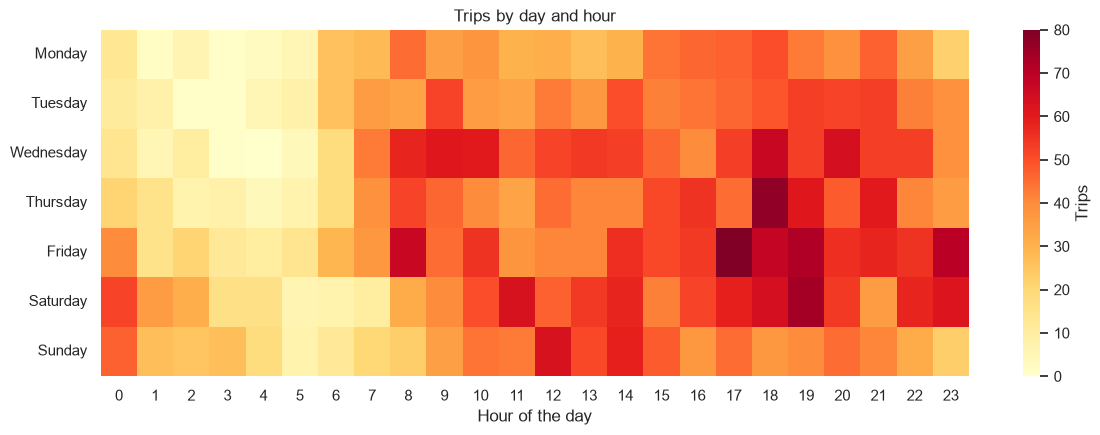

In [10]:
busy = pd.pivot_table(df, values="fare", index="weekday", columns="hour", aggfunc="count").reindex(order).fillna(0)

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(busy, cmap="YlOrRd", ax=ax, cbar_kws={"label": "Trips"})
ax.set_title("Trips by day and hour")
ax.set_xlabel("Hour of the day")
ax.set_ylabel("")
plt.show()

### Where do trips start, and what do they cost?

In [11]:
print(df["pickup_borough"].value_counts())
df.groupby("pickup_borough")[["fare", "tip", "distance"]].mean().round(2).sort_values("fare", ascending=False)

pickup_borough
Manhattan    5168
Queens        634
Brooklyn      374
Bronx          96
Unknown        15
Name: count, dtype: int64


,fare,tip,distance
pickup_borough,,,
Queens,25.35,3.06,7.61
Bronx,20.54,0.15,5.79
Brooklyn,16.46,0.99,4.16
Unknown,14.33,3.24,3.51
Manhattan,11.13,1.94,2.36


In [12]:
queens = df[df["pickup_borough"] == "Queens"].copy()
queens["airport"] = np.where(queens["pickup_zone"].str.contains("Airport"), "airport", "other")
queens.groupby("airport")["fare"].agg(["count", "mean"]).round(2)

,count,mean
airport,,
airport,286,38.19
other,348,14.80


Almost half of Queens pickups are at **JFK or LaGuardia airport**, and those trips cost far more. That's why Queens has the highest average fare.

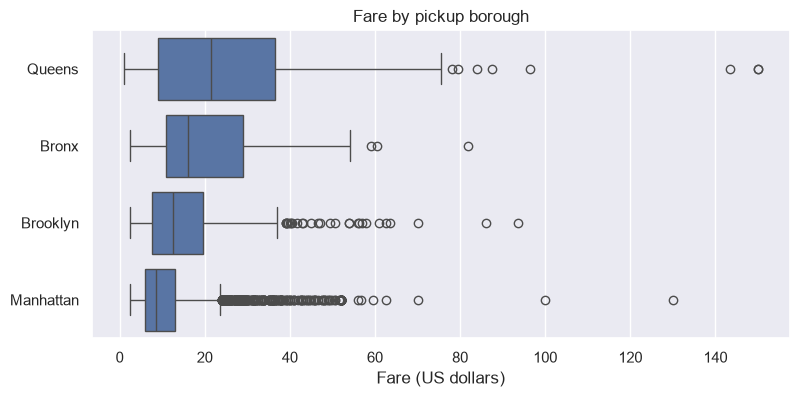

In [13]:
b = df[df["pickup_borough"] != "Unknown"]
o = b.groupby("pickup_borough")["fare"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=b, x="fare", y="pickup_borough", order=o, ax=ax)
ax.set_title("Fare by pickup borough")
ax.set_xlabel("Fare (US dollars)")
ax.set_ylabel("")
plt.show()

Correlation between distance and fare: 0.952


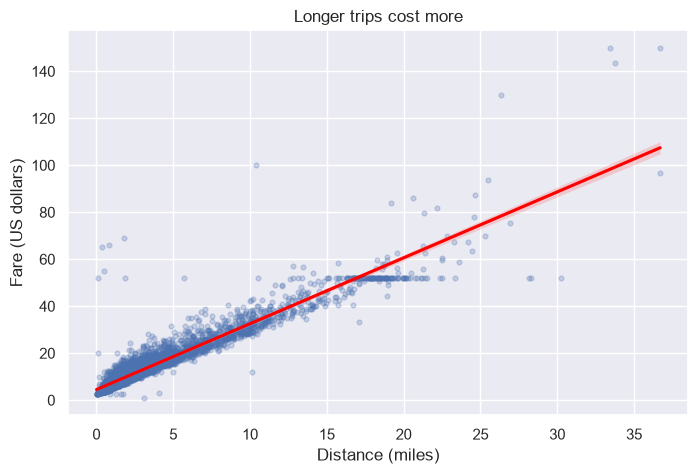

In [14]:
print("Correlation between distance and fare:", round(df["distance"].corr(df["fare"]), 3))

fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x="distance", y="fare", scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}, ax=ax)
ax.set_title("Longer trips cost more")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Fare (US dollars)")
plt.show()

### Yellow vs green taxis

In [15]:
pd.pivot_table(df, values="fare", index="pickup_borough", columns="color", aggfunc="count", margins=True, fill_value=0)

color,green,yellow,All
pickup_borough,,,
Bronx,81,15,96
Brooklyn,305,69,374
Manhattan,292,4876,5168
Queens,280,354,634
Unknown,0,15,15
All,958,5329,6287


### Who tips the most?

In [16]:
print(df.groupby("payment")["tip"].mean().round(2))
df.groupby("payment")["tipped"].value_counts()

payment
cash           0.00
credit card    2.76
unknown        0.00
Name: tip, dtype: float64


payment      tipped
cash         no        1776
credit card  yes       4037
             no         441
unknown      no          33
Name: count, dtype: int64

Every cash trip shows a tip of 0. Cash tips go straight to the driver and **aren't recorded**, so tip analysis has to use **card trips only**.

In [17]:
card = df[df["payment"] == "credit card"]
card.groupby("trip_length", observed=True)["tip_pct"].mean().round(1)

trip_length
short     30.0
medium    24.4
long      17.6
Name: tip_pct, dtype: float64

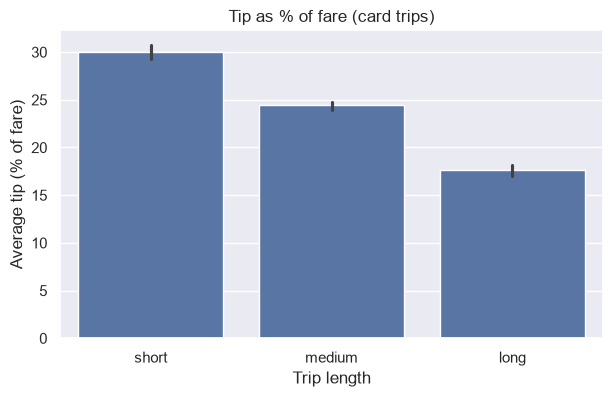

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=card, x="trip_length", y="tip_pct", order=["short", "medium", "long"], ax=ax)
ax.set_title("Tip as % of fare (card trips)")
ax.set_xlabel("Trip length")
ax.set_ylabel("Average tip (% of fare)")
plt.show()

## 6. Save the clean data

In [19]:
df.to_csv("data/taxi_trips_clean.csv", index=False)
df.shape

(6287, 20)

## 7. Findings
1. **The evening rush is the busiest time.** 6 p.m. has the most pickups (412), followed by 7 p.m. and 5 p.m. The busiest moment of the week is Friday at 5 p.m. (80 trips).
2. **Per day, Wednesday is busiest.** Friday has the most trips in total (1,085), but March 2019 had 5 Fridays. Per day, Wednesday leads (about 237 trips) and Sunday is quietest (about 170).
3. **Manhattan is where taxis work.** 82% of trips start there, but they're short (2.4 miles) and cheap (11.13 dollars on average).
4. **Airports make Queens the most expensive borough.** Queens has the highest average fare (25.35 dollars); 45% of its pickups are at JFK or LaGuardia, where the average fare is 38.19 dollars.
5. **Distance decides the price.** Distance and fare have a correlation of 0.95.
6. **Yellow and green taxis serve different areas.** Yellow taxis made 4,876 of the 5,168 Manhattan pickups; in Brooklyn, green taxis made 305 pickups to yellow's 69.
7. **Short trips get the biggest tips in percentage terms.** Card passengers tip 30% of the fare on short trips, but 17.6% on long ones.

**Limitations:** this is a sample from a single month; cash tips aren't recorded; and some groups are small (only 96 Bronx pickups), so their averages are less reliable.